In [19]:
   # Setup check: load the libraries this assignment uses
   import networkx as nx
   import numpy as np
   import matplotlib.pyplot as plt
   import scipy
   import pandas as pd
   import os
   import pickle
   import json
   import warnings
   import pandas as pd
   import random

   from collections import Counter
   print("networkx", nx.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)

networkx 3.5 | numpy 2.3.3 | scipy 1.16.2


   # NETS/PHYS 7052 — Assignment 02
   Jacopo Conti, Fall 2026

## Question 1 — Fitting power-law degree distributions

### 01.a.

In [ ]:
N = 10000
m = 4

# Initial sitaution : fully connected graph wioth 4 nodes (each degree = 3)
list_edges = [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)] # List of edges (6) in the initial graph
targets_pool = [] # A list of nodes to which the new node can connect. Picking uniformly from this list = picking a node with probability k_i / sum(k)
for a, b in list_edges: # where a and b are the two endpoints of each edge, we add both endpoints to the pool
    targets_pool.append(a)
    targets_pool.append(b)
print("Initial graph edges:", list_edges)
print("Targets pool:", targets_pool)

# Now, let's add a new node
new_node = 4
chosen = set() # an empty set ignores duplicates, so we get m distinct targets
while len(chosen) < m: # we repeat until we have m distinct targets
    chosen.add(random.choice(targets_pool)) # we p[ick randomly from the pool (P(k_i) = k_i / sum(k))]
print(chosen)

# Now, let's update each new link (new_node, target) adds both endpoints to the pool
for target in chosen: # we loop over the targets we just chose and add the new edges to the graph
    targets_pool.append(new_node)
    targets_pool.append(target)
    list_edges.append((new_node, target))

print("Chosen targets:", chosen)
print("Updated pool:", targets_pool)
print("Length:", len(targets_pool)) # check that the length of the pool is now 12 + 2 * m = 20

Initial graph edges: [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
Targets pool: [0, 1, 0, 2, 0, 3, 1, 2, 1, 3, 2, 3]
{0, 1, 2, 3}
Chosen targets: {0, 1, 2, 3}
Updated pool: [0, 1, 0, 2, 0, 3, 1, 2, 1, 3, 2, 3, 4, 0, 4, 1, 4, 2, 4, 3]
Length: 20


In [21]:
# Now let's add growth and checkpoints for the snapshots

N = 10000                          
m = 4

checkpoints = [10**2, 10**3, 10**4] # checkpoints for the degree sequence
snapshots = {} # dictionary where to save for later to plot

# Initial complete graph
list_edges = [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)]
targets_pool = []                  
for a, b in list_edges:
    targets_pool.append(a)
    targets_pool.append(b)

# Growth: add nodes 4, 5, ..., N-1
for new_node in range(4, N):       # one iteration = one new node
    chosen = set()                 
    while len(chosen) < m:
        chosen.add(random.choice(targets_pool))  

    for target in chosen:          # add the m new links
        targets_pool.append(new_node)
        targets_pool.append(target)
        list_edges.append((new_node, target))

    if new_node + 1 in checkpoints:
        snapshots[new_node + 1] = list(Counter(targets_pool).values())

print("Number of links:", len(list_edges))    
print("Pool length:", len(targets_pool))      

Number of links: 39990
Pool length: 79980


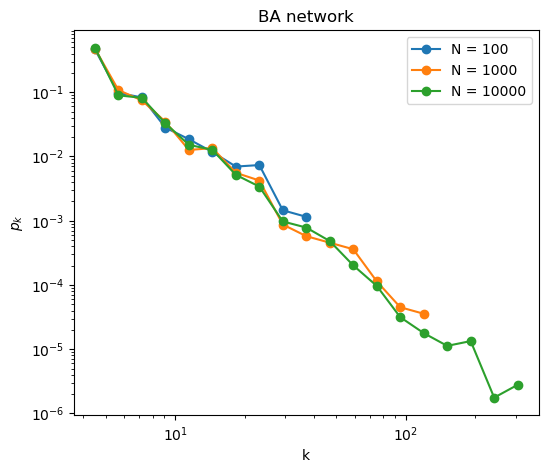

In [25]:
# Now let's log bin

k_min = m
k_max = max(snapshots[10**4])
bins = np.logspace(np.log10(k_min), np.log10(k_max), num=20) #20 edges → 19 bins, equally spaced in log scale

fig, ax = plt.subplots(figsize=(6, 5))

for n, degs in snapshots.items(): # one curve per snapshot
    pk, edges = np.histogram(degs, bins=bins, density=True) # desnity = dividing by total count and bin width > estimate of p_k
    centers = np.sqrt(edges[:-1] * edges[1:]) # geometric bin centers
    mask = pk > 0 # drop empty bins
    ax.plot(centers[mask], pk[mask], 'o-', label=f'N = {n}')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('k')
ax.set_ylabel('$p_k$')
ax.set_title('BA network')
ax.legend()
plt.show()

#### 1.b

1. Fit in one single snapshot with powerlaw and read y and k_min
2. Repeat for the three snapshot and put them in the legend
3. interpret witht he exact formula

In [29]:
import powerlaw

fit = powerlaw.Fit(snapshots[10**4], discrete=True)
print("gamma:", fit.alpha)
print("k_min:", fit.xmin)

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 95/95 [00:00<00:00, 802.81it/s]

gamma: 2.8588623046874995
k_min: 8.0


0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 17/17 [00:00<00:00, 665.10it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 43/43 [00:00<00:00, 943.33it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 95/95 [00:00<00:00, 822.00it/s]


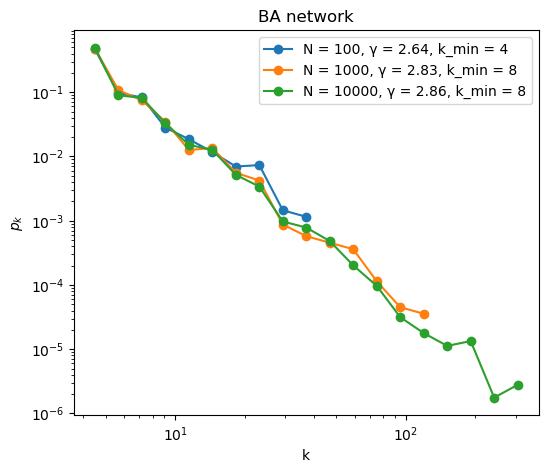

In [33]:
k_min = m
k_max = max(snapshots[10**4])
bins = np.logspace(np.log10(k_min), np.log10(k_max), num=20)
fits = {}

fig, ax = plt.subplots(figsize=(6, 5))

for n, degs in snapshots.items():
    fit = powerlaw.Fit(degs, discrete=True)
    fits[n] = fit

    pk, edges = np.histogram(degs, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])
    mask = pk > 0
    ax.plot(centers[mask], pk[mask], 'o-',  label=f'N = {n}, γ = {fit.alpha:.2f}, k_min = {fit.xmin:.0f}')   # fit results in the legend

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('k')
ax.set_ylabel('$p_k$')
ax.set_title('BA network')
ax.legend()
plt.show()

My estimation appraoch 3 as the network growth. For k >>> 0, K=1 or k+2 is = ca. to k (approximation). Therefore, the denominator is k^3. However, for k <<< 0 this change. The straight line representing the exact formula, in our log-log graph, change the slope accoridngly with k. We can calcualte the local_slope ion each point of the line as well. Biiger networks have enough nodes to allow a k_min woth a greater value, where the exact formula resemble more a k^-3. But however, this will aloways be less than 3.